# Stark Map

We calculate a Stark map for a rubidium atom in the state $|60S,m=1/2\rangle$. In this example, the electric field points along the quantization axis $z$ so that the magnetic quantum number is conserved. We take this into account for the construction of the basis. If we remove this conservation, we can calculate Stark maps for electric fields pointing in arbitrary directions. If you are interested in a Zeeman map instead of a Stark map, you can replace in this notebook the calls to ``set_electric_field`` by ``set_magnetic_field``.

We start by importing all required libraries and initializing the database of PairInteraction.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pairinteraction as pi
from pairinteraction.visualization.colormaps import alphamagma

if pi.Database.get_global_database() is None:
    pi.Database.initialize_global_database(download_missing=True)

We continue by defining a basis ``pi.BasisAtom`` for the Hamiltonian. The Hamiltonian is constructed and stored by ``pi.SystemAtom`` objects for different values of the electric field. After diagonalizing the systems, we have everything for plotting the Stark map.

In [ ]:
# Construct a basis around the state |60S,m=1/2>
ket = pi.KetAtom("Rb", n=60, l=0, m=0.5)
print(f"Ket of interest: {ket}")
ket_energy = ket.get_energy(unit="GHz")
basis = pi.BasisAtom.from_kets(ket, delta_n=3, delta_m=0)
print(f"Number of basis states: {basis.number_of_states}")

# Construct systems for different electric fields
electric_fields = np.linspace(0, 8, 50)
systems = [
    pi.SystemAtom(basis).set_electric_field([0, 0, e], unit="V/cm") for e in electric_fields
]

# Diagonalize the systems in parallel
pi.diagonalize(systems)

eigenenergies = [system.get_eigenenergies(unit="GHz") - ket_energy for system in systems]
overlaps = [system.get_eigenbasis().get_overlaps(ket) for system in systems]

Ket of interest: |Rb:60,S_1/2,1/2⟩
Number of basis states: 833


In the following, we use matplotlib to plot the Stark map. We visualize the overlap of the Stark-shifted states with $|60S,m=1/2\rangle$. PairInteraction's colormap `alphamagma` is transparent if the overlap is zero so that only the relevant states get colored.

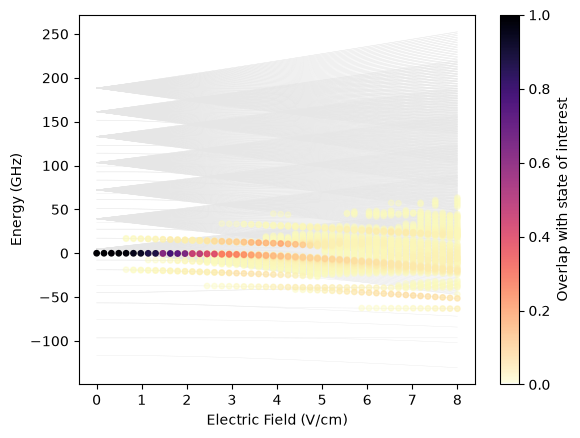

In [ ]:
fig, ax = plt.subplots()

ax.set_xlabel("Electric Field (V/cm)")
ax.set_ylabel("Energy (GHz)")

if all(len(es) == len(eigenenergies[0]) for es in eigenenergies):  # check if homogeneous shape
    ax.plot(electric_fields, np.array(eigenenergies), c="0.9", lw=0.25, zorder=-10)
else:
    for x, es in zip(electric_fields, eigenenergies, strict=True):
        ax.plot([x] * len(es), es, c="0.9", ls="None", marker=".", zorder=-10)

x_repeated = np.hstack(
    [val * np.ones_like(es) for val, es in zip(electric_fields, eigenenergies, strict=True)]
)
energies_flattened = np.hstack(eigenenergies)
overlaps_flattened = np.hstack(overlaps)
sorter = np.argsort(overlaps_flattened)

scat = ax.scatter(
    x_repeated[sorter],
    energies_flattened[sorter],
    c=overlaps_flattened[sorter],
    s=15,
    vmin=0,
    vmax=1,
    cmap=alphamagma,
)

fig.colorbar(scat, ax=ax, label="Overlap with state of interest")

plt.show()